In [ ]:
from pathlib import Path
import os, sys
_root = next((p for p in [Path.cwd().resolve(), *Path.cwd().resolve().parents] if (p / "REPOSITORY_PROVENANCE.json").is_file()), None)
if _root is None:
    raise RuntimeError("Start Jupyter inside this experiment repository.")
os.chdir(_root)
sys.path.insert(0, str(_root))


# Ten-qubit cubic majority policy with three- and four-local IQP rotations

This notebook performs a matched CartPole-v1/200 ablation of the published
ten-qubit, one-layer cubic-graph majority policy against the same policy with
ten trainable three-local rotations (R_{ZZZ}) and ten additional trainable
four-local rotations (R_{ZZZZ}). The already completed +10 R_{ZZZ} condition
is retained as an intermediate matched control without retraining it.

The comparison changes only the diagonal IQP generator set. Both conditions
use the same connected 3-regular graph, four-feature neural embedding on all ten
wires, local (R_Z) and graph-edge (R_{ZZ}) rotations, terminal Hadamards,
and deterministic majority on the nine measured wires (q_1,\ldots,q_9).
Wire (q_{10}) remains coupled but unmeasured.

## Confirmed production design

The new condition contains exactly ten fixed R_{ZZZ} rotations and ten fixed
R_{ZZZZ} rotations. The R_{ZZZ} triples and their initialization are identical
to the prior completed +10 R_{ZZZ} study. Ten quartets are sampled once, without
replacement and without inspecting performance; their angles use an independent
random stream. All common tensors are checked bitwise before the resumable
ten-seed sweep begins.

In [1]:
import os
os.environ.setdefault("OMP_NUM_THREADS", "1")
os.environ.setdefault("MKL_NUM_THREADS", "1")
os.environ.setdefault("KMP_DUPLICATE_LIB_OK", "TRUE")

import copy, hashlib, inspect, json, math, platform, subprocess, sys, time
from itertools import combinations
from pathlib import Path

import gymnasium as gym
import joblib
import matplotlib as mpl
import matplotlib.pyplot as plt
import networkx as nx
import numpy as np
import pandas as pd
import pennylane as qml
import scipy
import torch
from scipy import sparse

import qasp
from qasp.circuits.constructor import CircuitBuilder
from qasp.circuits.templates import IQPAnsatz
from qasp.feature_maps.templates import NeuralEmbedding
from qasp.rl.model import create_model
from qasp.rl.torchrl import REINFORCE

torch.set_num_threads(1)

ROOT = Path.cwd().resolve()
if ROOT.name == "tests":
    ROOT = ROOT.parent
RESULTS_DIR = ROOT / "tests" / "results" / "cartpole_10q_majority_rzzz_rzzzz_ablation"
RUNS_DIR = RESULTS_DIR / "runs"
FIGURES_DIR = RESULTS_DIR / "figures"
for directory in (RESULTS_DIR, RUNS_DIR, FIGURES_DIR):
    directory.mkdir(parents=True, exist_ok=True)

BASELINE_DIR = ROOT / "tests" / "results" / "majority_local_sector_ablation"
BASELINE_CONFIG_PATH = BASELINE_DIR / "experiment_config.json"
BASELINE_TRAIN_PATH = BASELINE_DIR / "training_episode_returns.csv"
BASELINE_EVAL_PATH = BASELINE_DIR / "heldout_evaluation_returns.csv"
BASELINE_METADATA_PATH = BASELINE_DIR / "run_metadata.csv"
BASELINE_AUDIT_PATH = BASELINE_DIR / "matched_initialization_audit.csv"
RZZZ_CONTROL_DIR = ROOT / "tests" / "results" / "cartpole_10q_majority_rzzz_ablation"

mpl.rcParams.update({
    "figure.dpi": 130, "savefig.dpi": 300, "font.size": 9,
    "axes.titlesize": 10, "axes.labelsize": 9, "legend.fontsize": 8,
    "lines.linewidth": 1.8, "pdf.fonttype": 42, "ps.fonttype": 42,
})

def git_output(*args):
    try:
        return subprocess.check_output(["git", *args], cwd=ROOT, text=True).strip()
    except Exception:
        return "unavailable"

CURRENT_BRANCH = git_output("branch", "--show-current")
CURRENT_COMMIT = git_output("rev-parse", "HEAD")
print("QASP root:", ROOT)
print("Current branch (recorded, never changed here):", CURRENT_BRANCH)
print("Current commit:", CURRENT_COMMIT)
print("Results:", RESULTS_DIR)
print("PennyLane", qml.__version__, "| PyTorch", torch.__version__, "| Gymnasium", gym.__version__)

QASP root: .
Current branch (recorded, never changed here): codex/circuit-cutting
Current commit: 8c9ccace59bfacfe4bc2df7155346aebe4506a2a
Results: ./tests/results/cartpole_10q_majority_rzzz_rzzzz_ablation
PennyLane 0.42.2 | PyTorch 2.7.0 | Gymnasium 1.0.0


## Locked matched protocol

The ten triples are copied exactly from the completed +10 R_{ZZZ} experiment.
The quartet ordering is sampled once, independently of any training outcome,
and its first ten distinct quartets are fixed for all seeds.

In [2]:
SEEDS = (3, 7, 11, 23, 37, 41, 43, 47, 53, 59)
N_QUBITS = 10
N_LAYERS = 1
MEASUREMENT_WIRES = tuple(range(9))
N_EPISODES = 500
N_EVAL_EPISODES = 100
MAX_STEPS = 200
FINAL_WINDOW = 50
MOVING_WINDOW = 20
SOLVED_THRESHOLD = 195.0
SOLVED_WINDOW = 100
N_JOBS = 2

RUN_PRODUCTION = True

RZZZ_TRIPLE_MASTER_SEED = 20261023
RZZZ_PARAMETER_MASTER_SEED = 20261024
RZZZZ_QUARTET_MASTER_SEED = 20261027
RZZZZ_PARAMETER_MASTER_SEED = 20261028

TRAINING = {
    "gamma": 0.99, "lr": 0.03, "lr_schedule": "constant (none)",
    "optimizer": "Adam(amsgrad=True)", "batch_episodes": 5,
    "normalize_mode": "clip", "normalize_returns": True,
    "baseline_type": "ema", "baseline_momentum": 0.05,
    "entropy_coef": 0.005, "max_grad_norm": 1.0,
}

EXPANDER_EDGES = (
    (0, 5), (0, 6), (0, 7), (1, 2), (1, 4),
    (1, 7), (2, 6), (2, 8), (3, 4), (3, 7),
    (3, 9), (4, 9), (5, 6), (5, 8), (8, 9),
)
EXPECTED_GRAPH_SEED = 1039606416
EXPECTED_GRAPH_GAP = 0.853351

all_triples = list(combinations(range(N_QUBITS), 3))
triple_rng = np.random.default_rng(RZZZ_TRIPLE_MASTER_SEED)
triple_order = [all_triples[int(i)] for i in triple_rng.permutation(len(all_triples))]
SELECTED_TRIPLES = tuple(triple_order[:10])
all_quartets = list(combinations(range(N_QUBITS), 4))
quartet_rng = np.random.default_rng(RZZZZ_QUARTET_MASTER_SEED)
quartet_order = [all_quartets[int(i)] for i in quartet_rng.permutation(len(all_quartets))]
SELECTED_QUARTETS = tuple(quartet_order[:10])
assert len(set(SELECTED_TRIPLES)) == 10
assert len(set(SELECTED_QUARTETS)) == 10

graph = nx.Graph()
graph.add_nodes_from(range(N_QUBITS)); graph.add_edges_from(EXPANDER_EDGES)
eigenvalues = np.linalg.eigvalsh(nx.to_numpy_array(graph, nodelist=range(N_QUBITS)))
graph_gap = float(eigenvalues[-1] - eigenvalues[-2])
assert nx.is_connected(graph) and all(degree == 3 for _, degree in graph.degree())
assert abs(graph_gap - EXPECTED_GRAPH_GAP) < 5e-7

print("Graph edges:", EXPANDER_EDGES)
print("Graph gap:", f"{graph_gap:.6f}", "| accepted seed:", EXPECTED_GRAPH_SEED)
print("Measured wires:", MEASUREMENT_WIRES, "| coupled/unmeasured wire: 9")
print("Selected RZZZ triples:", SELECTED_TRIPLES)
print("Selected RZZZZ quartets:", SELECTED_QUARTETS)
print("Production enabled:", RUN_PRODUCTION)

Graph edges: ((0, 5), (0, 6), (0, 7), (1, 2), (1, 4), (1, 7), (2, 6), (2, 8), (3, 4), (3, 7), (3, 9), (4, 9), (5, 6), (5, 8), (8, 9))
Graph gap: 0.853351 | accepted seed: 1039606416
Measured wires: (0, 1, 2, 3, 4, 5, 6, 7, 8) | coupled/unmeasured wire: 9
Selected RZZZ triples: ((2, 7, 8), (4, 7, 8), (1, 3, 8), (4, 5, 9), (2, 8, 9), (1, 2, 7), (2, 5, 7), (2, 5, 8), (0, 2, 7), (2, 3, 5))
Selected RZZZZ quartets: ((2, 3, 7, 9), (0, 3, 4, 5), (1, 4, 7, 9), (1, 5, 6, 7), (6, 7, 8, 9), (1, 2, 4, 9), (2, 3, 6, 7), (2, 6, 7, 8), (0, 1, 7, 8), (1, 3, 7, 9))
Production enabled: True


## Baseline provenance and compatibility audit

The reusable baseline is the completed controlled decoder comparison, not a
five-seed finite-shot subset. It contains ten 500-episode majority traces and
ten separately seeded 100-episode frozen-policy evaluations. Its configuration
and QASP-derived initial trainable tensors are checked below.

The historical paper depth-sweep table reports (192.13\pm5.23) for (L=1).
The controlled baseline reused here reports (191.88\pm5.19). The completed
+10 R_{ZZZ} experiment is also imported from durable seed-level traces. The
notebook keeps all provenance labels separate and uses matched seed-level data
for both paired contrasts.

In [3]:
for path in (BASELINE_CONFIG_PATH, BASELINE_TRAIN_PATH, BASELINE_EVAL_PATH,
             BASELINE_METADATA_PATH, BASELINE_AUDIT_PATH):
    if not path.exists():
        raise FileNotFoundError(path)

baseline_config = json.loads(BASELINE_CONFIG_PATH.read_text())
spec = baseline_config["architectures"]["expander_10_L1"]
assert tuple(baseline_config["seeds"]) == SEEDS
assert baseline_config["training_episodes"] == N_EPISODES
assert baseline_config["heldout_evaluation_episodes_per_seed"] == N_EVAL_EPISODES
assert baseline_config["trainer_side_step_cap"] == MAX_STEPS
assert baseline_config["training"] == TRAINING
assert spec["n_qubits"] == N_QUBITS and spec["n_layers"] == N_LAYERS
assert tuple(map(tuple, spec["edges"])) == EXPANDER_EDGES
assert tuple(spec["measurement_wires"]) == MEASUREMENT_WIRES
assert spec["initializer"] == "uniform"
assert spec["expected_quantum_parameters"] == 65
assert spec["accepted_networkx_seed"] == EXPECTED_GRAPH_SEED

baseline_train = pd.read_csv(BASELINE_TRAIN_PATH).query(
    "architecture == 'expander_10_L1' and policy == 'majority'"
).copy()
baseline_eval = pd.read_csv(BASELINE_EVAL_PATH).query(
    "architecture == 'expander_10_L1' and policy == 'majority'"
).copy()
baseline_metadata = pd.read_csv(BASELINE_METADATA_PATH).query(
    "architecture == 'expander_10_L1' and policy == 'majority'"
).copy()
baseline_audit = pd.read_csv(BASELINE_AUDIT_PATH).query(
    "architecture == 'expander_10_L1' and policy == 'majority'"
).copy()

assert baseline_train.groupby("seed").size().to_dict() == {seed: 500 for seed in SEEDS}
assert baseline_eval.groupby("seed").size().to_dict() == {seed: 100 for seed in SEEDS}
assert sorted(baseline_metadata.seed.astype(int)) == list(SEEDS)
assert sorted(baseline_audit.seed.astype(int)) == list(SEEDS)
assert baseline_audit.bitwise_identical.astype(bool).all()
assert set(baseline_metadata.execution_backend) == {"analytic_torch_statevector"}
assert set(baseline_metadata.n_parameters.astype(int)) == {65}

baseline_seed_final50 = (baseline_train.sort_values(["seed", "episode"])
    .groupby("seed").tail(FINAL_WINDOW).groupby("seed")["return"].mean()
    .reindex(SEEDS))
baseline_seed_eval = baseline_eval.groupby("seed")["return"].mean().reindex(SEEDS)
baseline_mean = float(baseline_seed_final50.mean())
baseline_sem = float(baseline_seed_final50.std(ddof=1) / math.sqrt(len(SEEDS)))
print(f"Controlled baseline training final-50: {baseline_mean:.2f} +/- {baseline_sem:.2f}")
print(f"Controlled baseline held-out: {baseline_seed_eval.mean():.3f} +/- "
      f"{baseline_seed_eval.std(ddof=1)/math.sqrt(len(SEEDS)):.3f}")
print("Paper depth-sweep value (context only, not paired data): 192.13 +/- 5.23")

rzzz_config = json.loads((RZZZ_CONTROL_DIR / "experiment_config.json").read_text())
rzzz_train = pd.read_csv(RZZZ_CONTROL_DIR / "episode_returns.csv").query(
    "condition == 'majority + 10 RZZZ'"
).copy()
rzzz_eval = pd.read_csv(RZZZ_CONTROL_DIR / "heldout_evaluation_returns.csv").query(
    "condition == 'majority + 10 RZZZ'"
).copy()
rzzz_runs = pd.read_csv(RZZZ_CONTROL_DIR / "run_metadata.csv")
rzzz_audit = pd.read_csv(RZZZ_CONTROL_DIR / "matched_initialization_audit.csv")
assert rzzz_config["seeds"] == list(SEEDS)
assert rzzz_config["selected_triples"] == [list(t) for t in SELECTED_TRIPLES]
assert rzzz_config["rzzz_gate_count"] == 10
assert rzzz_config["augmented_parameter_count"] == 75
assert rzzz_train.groupby("seed").size().to_dict() == {seed: 500 for seed in SEEDS}
assert rzzz_eval.groupby("seed").size().to_dict() == {seed: 100 for seed in SEEDS}
assert sorted(rzzz_runs.seed.astype(int)) == list(SEEDS)
assert rzzz_audit.shared_tensors_bitwise_identical.astype(bool).all()
print("Imported matched +10 RZZZ control: final-50",
      f"{rzzz_train.sort_values(['seed','episode']).groupby('seed').tail(50).groupby('seed')['return'].mean().mean():.3f}")

Controlled baseline training final-50: 191.88 +/- 5.19
Controlled baseline held-out: 194.687 +/- 2.057
Paper depth-sweep value (context only, not paired data): 192.13 +/- 5.23
Imported matched +10 RZZZ control: final-50 193.782


## Exact QASP circuit and validated statevector implementation

`CubicRZZZRZZZZAnsatz` is a QASP `CircuitBuilder`-compatible one-layer program:

\[
H^{\otimes 10}\;D_Z(\mathbf{s};W,\alpha,\beta,\gamma,\delta)\;H^{\otimes 10},
\]

where (D_Z) contains the neural (R_Z) encoding, ten trainable local
(R_Z) gates, the fixed graph's fifteen (R_{ZZ}) gates, the ten selected
(R_{ZZZ}) gates, and the ten selected (R_{ZZZZ}) gates. The native QASP sparse majority projector is retained as
the reference. The faster differentiable statevector implementation is used
for production only after probability and analytic-gradient agreement.

In [4]:
def majority_pi0_diagonal(n_qubits=N_QUBITS, measured=MEASUREMENT_WIRES):
    states = np.arange(1 << n_qubits, dtype=np.int64)
    shifts = np.asarray([n_qubits - 1 - wire for wire in measured])
    bits = ((states[:, None] >> shifts[None, :]) & 1)
    # Nine measured bits: action 0 iff zeros are the strict majority.
    return (bits.sum(axis=1) <= len(measured) // 2).astype(np.float64)


class CubicRZZZRZZZZAnsatz:
    def __init__(self, triples, quartets):
        self.n_qubits = N_QUBITS
        self.n_layers = 1
        self.feature_map = NeuralEmbedding(
            n_qubits=N_QUBITS, features=4, rotations="Z"
        )
        self.reuploading = True
        self.include_single_qubit = True
        self.edges = list(EXPANDER_EDGES)
        self.triples = [tuple(map(int, triple)) for triple in triples]
        self.quartets = [tuple(map(int, quartet)) for quartet in quartets]
        self.z_gates = None; self.parity_gates = None; self.CNOT_Gates = None

    def get_param_shapes(self):
        return [(N_QUBITS * 4,),
                (N_QUBITS + len(self.edges) + len(self.triples) + len(self.quartets),)]

    def __call__(self, inputs=None, input_scaling_params=None, params=None):
        for wire in range(N_QUBITS):
            qml.Hadamard(wires=wire)
        self.feature_map(inputs, input_scaling_params=input_scaling_params)
        for wire in range(N_QUBITS):
            qml.RZ(params[wire], wires=wire)
        offset = N_QUBITS
        for index, edge in enumerate(self.edges):
            qml.PauliRot(params[offset + index], "ZZ", wires=list(edge))
        offset += len(self.edges)
        for index, triple in enumerate(self.triples):
            qml.PauliRot(params[offset + index], "ZZZ", wires=list(triple))
        offset += len(self.triples)
        for index, quartet in enumerate(self.quartets):
            qml.PauliRot(params[offset + index], "ZZZZ", wires=list(quartet))
        for wire in range(N_QUBITS):
            qml.Hadamard(wires=wire)


def qasp_initial_state(seed):
    config = {
        "ansatz": "IQPAnsatz",
        "ansatz_config": {
            "n_layers": 1, "imprimitive_pattern": list(EXPANDER_EDGES),
            "reuploading": True, "include_single_qubit": True,
        },
        "feature_map": "NeuralEmbedding",
        "feature_map_config": {"features": 4, "rotations": "Z"},
        "n_actions": 2, "init": "uniform",
        "device": "lightning.qubit", "diff_method": "adjoint", "shots": None,
        "softmax_activation": False, "output_scaling": None, "torchrl": False,
        "measurement_qubits": list(MEASUREMENT_WIRES),
        "parity_cnot_decomposition": False, "policy": "parity-like",
        "training_method": "expectation", "enable_mpi": False,
    }
    torch.manual_seed(int(seed)); np.random.seed(int(seed))
    model = create_model("PQCBorn", config, n_qubits=N_QUBITS)
    state = {key: value.detach().cpu().clone()
             for key, value in model.qlayer.state_dict().items()}
    del model
    return state


def rzzz_parameter_seed(seed):
    sequence = np.random.SeedSequence([RZZZ_PARAMETER_MASTER_SEED, int(seed)])
    return int(sequence.generate_state(1, dtype=np.uint32)[0])


def rzzzz_parameter_seed(seed):
    sequence = np.random.SeedSequence([RZZZZ_PARAMETER_MASTER_SEED, int(seed)])
    return int(sequence.generate_state(1, dtype=np.uint32)[0])


def initial_angles(seed, count, seed_function):
    generator = torch.Generator(device="cpu")
    generator.manual_seed(seed_function(seed))
    return torch.empty(count, dtype=torch.float32).uniform_(
        -math.pi, math.pi, generator=generator
    )


def tensor_hash(*tensors):
    return hashlib.sha256(b"".join(
        tensor.detach().cpu().contiguous().numpy().tobytes() for tensor in tensors
    )).hexdigest()


class NativeQASPMajority(torch.nn.Module):
    def __init__(self, triples, quartets, seed):
        super().__init__()
        ansatz = CubicRZZZRZZZZAnsatz(triples, quartets)
        builder = CircuitBuilder(n_qubits=N_QUBITS)
        builder.set_ansatz(ansatz)
        matrix = sparse.diags(
            majority_pi0_diagonal(), format="csr", dtype=np.float64
        )
        observable = qml.SparseHamiltonian(matrix, wires=range(N_QUBITS))
        builder.set_measurement("expectation", wires=range(N_QUBITS),
                                observables=[observable])
        builder.build()
        builder.compile(device="lightning.qubit", diff_method="adjoint",
                        shots=None, device_vjp=False, batch_obs=False)
        torch.manual_seed(int(seed)); np.random.seed(int(seed))
        self.qlayer = builder.create_torchlayer(initialization="uniform")
        self.builder = builder
        self.triples = tuple(triples)
        self.quartets = tuple(quartets)

    def forward(self, x):
        p0 = self.qlayer(x)
        if p0.ndim and p0.shape[-1] == 1:
            p0 = p0.squeeze(-1)
        probs = torch.stack((p0, 1.0 - p0), dim=-1).clamp_min(0.0)
        return probs / probs.sum(dim=-1, keepdim=True).clamp_min(
            torch.finfo(probs.dtype).eps
        )


class ExactTorchCubicMajority(torch.nn.Module):
    def __init__(self, triples, quartets, seed):
        super().__init__()
        initial = qasp_initial_state(seed)
        self.input_scaling_params = torch.nn.Parameter(
            initial["input_scaling_params"].clone()
        )
        self.params = torch.nn.Parameter(initial["params"].clone())
        self.rzzz_params = torch.nn.Parameter(
            initial_angles(seed, len(triples), rzzz_parameter_seed)
        )
        self.rzzzz_params = torch.nn.Parameter(
            initial_angles(seed, len(quartets), rzzzz_parameter_seed)
        )
        self.triples = tuple(tuple(map(int, t)) for t in triples)
        self.quartets = tuple(tuple(map(int, q)) for q in quartets)
        self.forward_calls = 0

        dimension = 1 << N_QUBITS
        basis = torch.arange(dimension, dtype=torch.long)
        shifts = torch.arange(N_QUBITS - 1, -1, -1, dtype=torch.long)
        bits = ((basis[:, None] >> shifts[None, :]) & 1).to(torch.float32)
        z_signs = (1.0 - 2.0 * bits).T
        self.register_buffer("z_signs", z_signs)
        self.register_buffer("zz_signs", torch.stack([
            z_signs[left] * z_signs[right] for left, right in EXPANDER_EDGES
        ]))
        if self.triples:
            rzzz_signs = torch.stack([
                z_signs[a] * z_signs[b] * z_signs[c]
                for a, b, c in self.triples
            ])
        else:
            rzzz_signs = torch.empty((0, dimension), dtype=torch.float32)
        self.register_buffer("rzzz_signs", rzzz_signs)
        if self.quartets:
            rzzzz_signs = torch.stack([
                z_signs[a] * z_signs[b] * z_signs[c] * z_signs[d]
                for a, b, c, d in self.quartets
            ])
        else:
            rzzzz_signs = torch.empty((0, dimension), dtype=torch.float32)
        self.register_buffer("rzzzz_signs", rzzzz_signs)
        measured_index = torch.zeros(dimension, dtype=torch.long)
        for wire in MEASUREMENT_WIRES:
            measured_index = (measured_index << 1) | bits[:, wire].to(torch.long)
        self.register_buffer("measured_index", measured_index)
        measured_states = np.arange(1 << len(MEASUREMENT_WIRES), dtype=np.int64)
        measured_weights = np.asarray([
            int(value).bit_count() for value in measured_states
        ])
        self.register_buffer("pi0_basis", torch.as_tensor(
            measured_weights <= len(MEASUREMENT_WIRES) // 2,
            dtype=torch.float32,
        ))

    @staticmethod
    def _hadamards(state):
        result = state; width = 1; dimension = state.shape[-1]
        while width < dimension:
            blocks = result.reshape(*result.shape[:-1], -1, 2, width)
            left, right = blocks[..., 0, :], blocks[..., 1, :]
            result = torch.stack((left + right, left - right), dim=-2)
            result = result.reshape(*state.shape[:-1], dimension) / math.sqrt(2.0)
            width *= 2
        return result

    def exact_basis_probs(self, states):
        states = torch.as_tensor(states, dtype=torch.float32)
        dimension = 1 << N_QUBITS
        batch_shape = states.shape[:-1]
        state = torch.ones(*batch_shape, dimension, dtype=torch.complex64)
        state = state / math.sqrt(dimension)
        weights = self.input_scaling_params.reshape(N_QUBITS, 4)
        encoded = torch.einsum("...f,qf->...q", states, weights)
        angle = torch.einsum("...q,qd->...d", encoded, self.z_signs)
        angle = angle + torch.einsum("q,qd->d", self.params[:N_QUBITS], self.z_signs)
        angle = angle + torch.einsum("e,ed->d", self.params[N_QUBITS:], self.zz_signs)
        if len(self.triples):
            angle = angle + torch.einsum("t,td->d", self.rzzz_params, self.rzzz_signs)
        if len(self.quartets):
            angle = angle + torch.einsum("u,ud->d", self.rzzzz_params, self.rzzzz_signs)
        state = state * torch.exp(-0.5j * angle)
        state = self._hadamards(state)
        full = state.abs().square().real
        measured_dimension = 1 << len(MEASUREMENT_WIRES)
        flat = full.reshape(-1, dimension)
        measured = full.new_zeros((flat.shape[0], measured_dimension))
        measured.scatter_add_(
            1, self.measured_index[None, :].expand(flat.shape[0], -1), flat
        )
        return measured.reshape(*batch_shape, measured_dimension)

    def forward(self, x):
        self.forward_calls += 1
        basis = self.exact_basis_probs(x)
        p0 = torch.einsum("...d,d->...", basis, self.pi0_basis)
        probs = torch.stack((p0, 1.0 - p0), dim=-1).clamp_min(0.0)
        return probs / probs.sum(dim=-1, keepdim=True).clamp_min(
            torch.finfo(probs.dtype).eps
        )

## Preflight validation of the four-local extension

These tests do not train. They verify:

- the live QASP base tensors reproduce every saved baseline initialization hash;
- shared base tensors and R_{ZZZ} tensors are bitwise identical to the prior controls;
- the R_{ZZZZ} angles use a separate deterministic random stream;
- setting the four-local angles to zero exactly recovers the +10 R_{ZZZ} circuit;
- QASP and the accelerated implementation agree in probabilities and gradients;
- the native tape contains precisely the intended (R_Z), (R_{ZZ}), (R_{ZZZ}),
  and (R_{ZZZZ}) gates and the nine-bit majority projector.

In [5]:
baseline_hash_by_seed = baseline_audit.set_index("seed").trainable_parameter_sha256
rzzz_hash_by_seed = rzzz_audit.set_index("seed").extra_parameter_sha256
for seed in SEEDS:
    initial = qasp_initial_state(seed)
    live_hash = tensor_hash(initial["input_scaling_params"], initial["params"])
    assert live_hash == baseline_hash_by_seed.loc[seed]
    expected_rzzz = initial_angles(seed, 10, rzzz_parameter_seed)
    assert tensor_hash(expected_rzzz) == rzzz_hash_by_seed.loc[seed]
print("All 10 base and RZZZ initialization hashes match their saved controls.")

validation_state = torch.tensor([0.2, -0.1, 0.05, 0.3], dtype=torch.float32)
seed = SEEDS[0]
initial = qasp_initial_state(seed)
fast = ExactTorchCubicMajority(SELECTED_TRIPLES, SELECTED_QUARTETS, seed)
assert torch.equal(fast.input_scaling_params.detach(), initial["input_scaling_params"])
assert torch.equal(fast.params.detach(), initial["params"])
assert tensor_hash(fast.input_scaling_params, fast.params) == baseline_hash_by_seed.loc[seed]
assert tensor_hash(fast.rzzz_params) == rzzz_hash_by_seed.loc[seed]
assert sum(p.numel() for p in fast.parameters()) == 85

rzzz_only = ExactTorchCubicMajority(SELECTED_TRIPLES, (), seed)
zero_quartets = ExactTorchCubicMajority(SELECTED_TRIPLES, SELECTED_QUARTETS, seed)
with torch.no_grad():
    zero_quartets.rzzzz_params.zero_()
torch.testing.assert_close(rzzz_only(validation_state), zero_quartets(validation_state),
                           atol=2e-7, rtol=2e-7)
(-torch.log(rzzz_only(validation_state)[0])).backward()
(-torch.log(zero_quartets(validation_state)[0])).backward()
for left, right in ((rzzz_only.input_scaling_params.grad, zero_quartets.input_scaling_params.grad),
                    (rzzz_only.params.grad, zero_quartets.params.grad),
                    (rzzz_only.rzzz_params.grad, zero_quartets.rzzz_params.grad)):
    torch.testing.assert_close(left, right, atol=2e-6, rtol=2e-5)

native = NativeQASPMajority(SELECTED_TRIPLES, SELECTED_QUARTETS, seed)
combined = torch.cat((fast.params.detach(), fast.rzzz_params.detach(),
                      fast.rzzzz_params.detach()))
native.qlayer.load_state_dict({
    "input_scaling_params": fast.input_scaling_params.detach().clone(),
    "params": combined.clone(),
})
expected = native(validation_state); actual = fast(validation_state)
torch.testing.assert_close(actual, expected, atol=3e-6, rtol=3e-6)
(-torch.log(expected[0])).backward(); (-torch.log(actual[0])).backward()
native_grad = torch.cat((native.qlayer.input_scaling_params.grad.reshape(-1),
                         native.qlayer.params.grad.reshape(-1)))
fast_grad = torch.cat((fast.input_scaling_params.grad.reshape(-1),
                       fast.params.grad.reshape(-1), fast.rzzz_params.grad.reshape(-1),
                       fast.rzzzz_params.grad.reshape(-1)))
torch.testing.assert_close(fast_grad, native_grad, atol=4e-5, rtol=5e-4)

tape = qml.tape.make_qscript(native.builder.circuit)(
    inputs=validation_state,
    input_scaling_params=native.qlayer.input_scaling_params,
    params=native.qlayer.params,
)
words = [op.hyperparameters.get("pauli_word") for op in tape.operations
         if op.name == "PauliRot"]
audit = {
    "trainable_parameter_count": sum(p.numel() for p in fast.parameters()),
    "n_hadamards": sum(op.name == "Hadamard" for op in tape.operations),
    "n_embedding_RZ": words.count("Z"),
    "n_local_RZ": sum(op.name == "RZ" for op in tape.operations),
    "n_RZZ": words.count("ZZ"), "n_RZZZ": words.count("ZZZ"),
    "n_RZZZZ": words.count("ZZZZ"), "n_measurements": len(tape.measurements),
    "shared_initialization_hash": tensor_hash(fast.input_scaling_params, fast.params),
    "rzzz_initialization_hash": tensor_hash(fast.rzzz_params),
    "rzzzz_initialization_hash": tensor_hash(fast.rzzzz_params),
    "max_probability_abs_error": float((actual - expected).abs().max()),
    "max_gradient_abs_error": float((fast_grad - native_grad).abs().max()),
    "zero_rzzzz_angle_equivalence_passed": True,
    "triples": [list(t) for t in SELECTED_TRIPLES],
    "quartets": [list(q) for q in SELECTED_QUARTETS],
}
assert (audit["n_hadamards"], audit["n_embedding_RZ"], audit["n_local_RZ"],
        audit["n_RZZ"], audit["n_RZZZ"], audit["n_RZZZZ"], audit["n_measurements"]) == (20, 10, 10, 15, 10, 10, 1)
preflight_rows = [audit]
preflight_df = pd.DataFrame(preflight_rows)
display(preflight_df[["trainable_parameter_count", "n_embedding_RZ", "n_local_RZ",
                      "n_RZZ", "n_RZZZ", "n_RZZZZ",
                      "max_probability_abs_error", "max_gradient_abs_error"]])
del rzzz_only, zero_quartets, native, fast

All 10 base and RZZZ initialization hashes match their saved controls.


,trainable_parameter_count,n_embedding_RZ,n_local_RZ,n_RZZ,n_RZZZ,n_RZZZZ,max_probability_abs_error,max_gradient_abs_error
0,85,10,10,15,10,10,2.086163e-07,6.705523e-08


## Matched training and held-out evaluation

Only the augmented condition needs to run: the compatible controlled baseline
is reused from durable seed-level traces. Before every augmented rollout,
PyTorch, NumPy, the Gymnasium environment, and its action space are reset to the
same training seed as the baseline. Extra-angle initialization uses a separate
local generator and therefore cannot advance the shared initialization or
action-sampling stream. Checkpoints make the sweep resumable.

In [6]:
class TrackedREINFORCE(REINFORCE):
    def __post_init__(self):
        self.optimizer_updates = 0
        super().__post_init__()

    def _optimise_loss(self, loss):
        super()._optimise_loss(loss)
        self.optimizer_updates += 1


def strict_solved_episode(returns, window=SOLVED_WINDOW, threshold=SOLVED_THRESHOLD):
    values = np.asarray(returns, dtype=float)
    if len(values) < window:
        return np.nan
    rolling = np.convolve(values, np.ones(window) / window, mode="valid")
    hits = np.flatnonzero(rolling >= threshold)
    return float(hits[0] + window) if len(hits) else np.nan


def source_freeze_episode(returns):
    for episode in range(TRAINING["batch_episodes"], len(returns) + 1,
                         TRAINING["batch_episodes"]):
        if np.mean(returns[max(0, episode - SOLVED_WINDOW):episode]) >= SOLVED_THRESHOLD:
            return float(episode)
    return np.nan


def evaluate_frozen(policy, seed):
    policy.eval()
    env = gym.make("CartPole-v1")
    returns = []
    scale = torch.tensor([2.4, 3.0, 0.2095, 3.5], dtype=torch.float32)
    with torch.no_grad():
        for episode in range(N_EVAL_EPISODES):
            env_seed = 1_000_000 + 10_000 * int(seed) + episode
            action_seed = 2_000_000 + 10_000 * int(seed) + episode
            state, _ = env.reset(seed=env_seed)
            generator = torch.Generator().manual_seed(action_seed)
            total = 0.0
            for _ in range(MAX_STEPS):
                x = torch.clamp(torch.as_tensor(state, dtype=torch.float32) /
                                scale, -3.0, 3.0)
                probs = policy(x)
                action = int(torch.multinomial(probs, 1, generator=generator).item())
                state, reward, terminated, truncated, _ = env.step(action)
                total += float(reward)
                if terminated or truncated:
                    break
            returns.append(total)
    env.close()
    return np.asarray(returns, dtype=float)


def run_one_augmented(seed, triples, quartets):
    run_name = f"expander_10_L1__majority_rzzz10_rzzzz10__seed_{seed}"
    npz_path = RUNS_DIR / f"{run_name}.npz"
    pt_path = RUNS_DIR / f"{run_name}.pt"
    json_path = RUNS_DIR / f"{run_name}.json"
    if npz_path.exists() and pt_path.exists() and json_path.exists():
        arrays = np.load(npz_path)
        metadata = json.loads(json_path.read_text())
        if (len(arrays["training_returns"]) == N_EPISODES and
                len(arrays["evaluation_returns"]) == N_EVAL_EPISODES and
                metadata.get("triples") == [list(t) for t in triples] and
                metadata.get("quartets") == [list(q) for q in quartets]):
            return metadata

    start = time.perf_counter()
    policy = ExactTorchCubicMajority(triples, quartets, seed)
    initial_shared_hash = tensor_hash(policy.input_scaling_params, policy.params)
    initial_rzzz_hash = tensor_hash(policy.rzzz_params)
    initial_rzzzz_hash = tensor_hash(policy.rzzzz_params)
    assert initial_shared_hash == baseline_hash_by_seed.loc[seed]
    assert initial_rzzz_hash == rzzz_hash_by_seed.loc[seed]

    agent = TrackedREINFORCE(
        policy=policy, env_name="CartPole-v1", gamma=TRAINING["gamma"],
        lr=TRAINING["lr"], max_steps=MAX_STEPS,
        batch_episodes=TRAINING["batch_episodes"], logits=False,
        normalize_mode=TRAINING["normalize_mode"],
        normalize_returns=TRAINING["normalize_returns"],
        entropy_coef=TRAINING["entropy_coef"],
        baseline_type=TRAINING["baseline_type"],
        baseline_momentum=TRAINING["baseline_momentum"],
        max_grad_norm=TRAINING["max_grad_norm"],
    )
    # Restore independent rollout streams after all parameter construction.
    torch.manual_seed(int(seed)); np.random.seed(int(seed))
    agent.env.reset(seed=int(seed)); agent.env.action_space.seed(int(seed))
    train_start = time.perf_counter()
    training_returns = np.asarray(
        agent.train(num_episodes=N_EPISODES, log_every=50), dtype=float
    )
    training_seconds = time.perf_counter() - train_start
    training_calls = int(policy.forward_calls)
    eval_start = time.perf_counter()
    evaluation_returns = evaluate_frozen(policy, seed)
    evaluation_seconds = time.perf_counter() - eval_start
    evaluation_calls = int(policy.forward_calls) - training_calls
    agent.env.close()

    torch.save({
        "seed": int(seed), "triples": list(triples), "quartets": list(quartets),
        "state_dict": {key: value.detach().cpu() for key, value in policy.state_dict().items()},
        "training_returns": training_returns, "evaluation_returns": evaluation_returns,
    }, pt_path)
    np.savez_compressed(npz_path, training_returns=training_returns,
                        evaluation_returns=evaluation_returns)
    metadata = {
        "run_id": run_name, "seed": int(seed), "condition": "majority_rzzz_rzzzz",
        "n_qubits": N_QUBITS, "depth": N_LAYERS,
        "measurement_wires": list(MEASUREMENT_WIRES),
        "n_rzzz_gates": len(triples), "triples": [list(t) for t in triples],
        "n_rzzzz_gates": len(quartets), "quartets": [list(q) for q in quartets],
        "n_parameters": sum(p.numel() for p in policy.parameters()),
        "initial_shared_parameter_sha256": initial_shared_hash,
        "baseline_shared_parameter_sha256": baseline_hash_by_seed.loc[seed],
        "initial_rzzz_parameter_sha256": initial_rzzz_hash,
        "rzzz_parameter_seed": rzzz_parameter_seed(seed),
        "initial_rzzzz_parameter_sha256": initial_rzzzz_hash,
        "rzzzz_parameter_seed": rzzzz_parameter_seed(seed),
        "execution_backend": "validated_analytic_torch_statevector",
        "measurement_path": "nine_bit_majority_exact_probabilities",
        "training_final_50": float(training_returns[-FINAL_WINDOW:].mean()),
        "evaluation_mean": float(evaluation_returns.mean()),
        "evaluation_std": float(evaluation_returns.std(ddof=1)),
        "strict_solved_episode": strict_solved_episode(training_returns),
        "optimizer_freeze_episode": source_freeze_episode(training_returns),
        "optimizer_updates": int(agent.optimizer_updates),
        "training_forward_circuit_calls": training_calls,
        "evaluation_forward_circuit_calls": evaluation_calls,
        "training_seconds": training_seconds, "evaluation_seconds": evaluation_seconds,
        "total_seconds": time.perf_counter() - start,
        "checkpoint_npz": str(npz_path), "checkpoint_pt": str(pt_path),
    }
    json_path.write_text(json.dumps(metadata, indent=2, allow_nan=True))
    print("DONE", run_name, "final50", f"{metadata['training_final_50']:.2f}",
          "eval", f"{metadata['evaluation_mean']:.2f}",
          "seconds", f"{metadata['total_seconds']:.1f}", flush=True)
    return metadata

## Production execution

The human-confirmed configuration contains ten R_{ZZZ} and ten R_{ZZZZ}
rotations with `RUN_PRODUCTION=True`. No other protocol field is changed. Each
seed-level checkpoint is reused only after validating its dimensions and fixed
triple/quartet sets.

In [7]:
production_metadata = []
if not RUN_PRODUCTION:
    print("PRODUCTION READY for 10 RZZZ + 10 RZZZZ, but RUN_PRODUCTION=False.")
else:
    production_metadata = joblib.Parallel(
        n_jobs=N_JOBS, backend="loky", verbose=10
    )(joblib.delayed(run_one_augmented)(seed, SELECTED_TRIPLES, SELECTED_QUARTETS)
      for seed in SEEDS)
    assert len(production_metadata) == len(SEEDS)

[Parallel(n_jobs=2)]: Using backend LokyBackend with 2 concurrent workers.


[Parallel(n_jobs=2)]: Done   1 tasks      | elapsed:    3.5s
[Parallel(n_jobs=2)]: Done   4 tasks      | elapsed:    3.6s
[Parallel(n_jobs=2)]: Done  10 out of  10 | elapsed:    3.6s finished


## Aggregation, paired inference, and publication figure

When all ten new checkpoints exist, this cell combines them with the controlled
baseline and the prior +10 R_{ZZZ} condition. Each seed is smoothed separately
with a 20-episode moving window before the mean and standard error are computed.
Final-50 and held-out statistics use the seed—not the episode—as the independent
unit. Seed-level bootstrap intervals compare the new model with both controls.

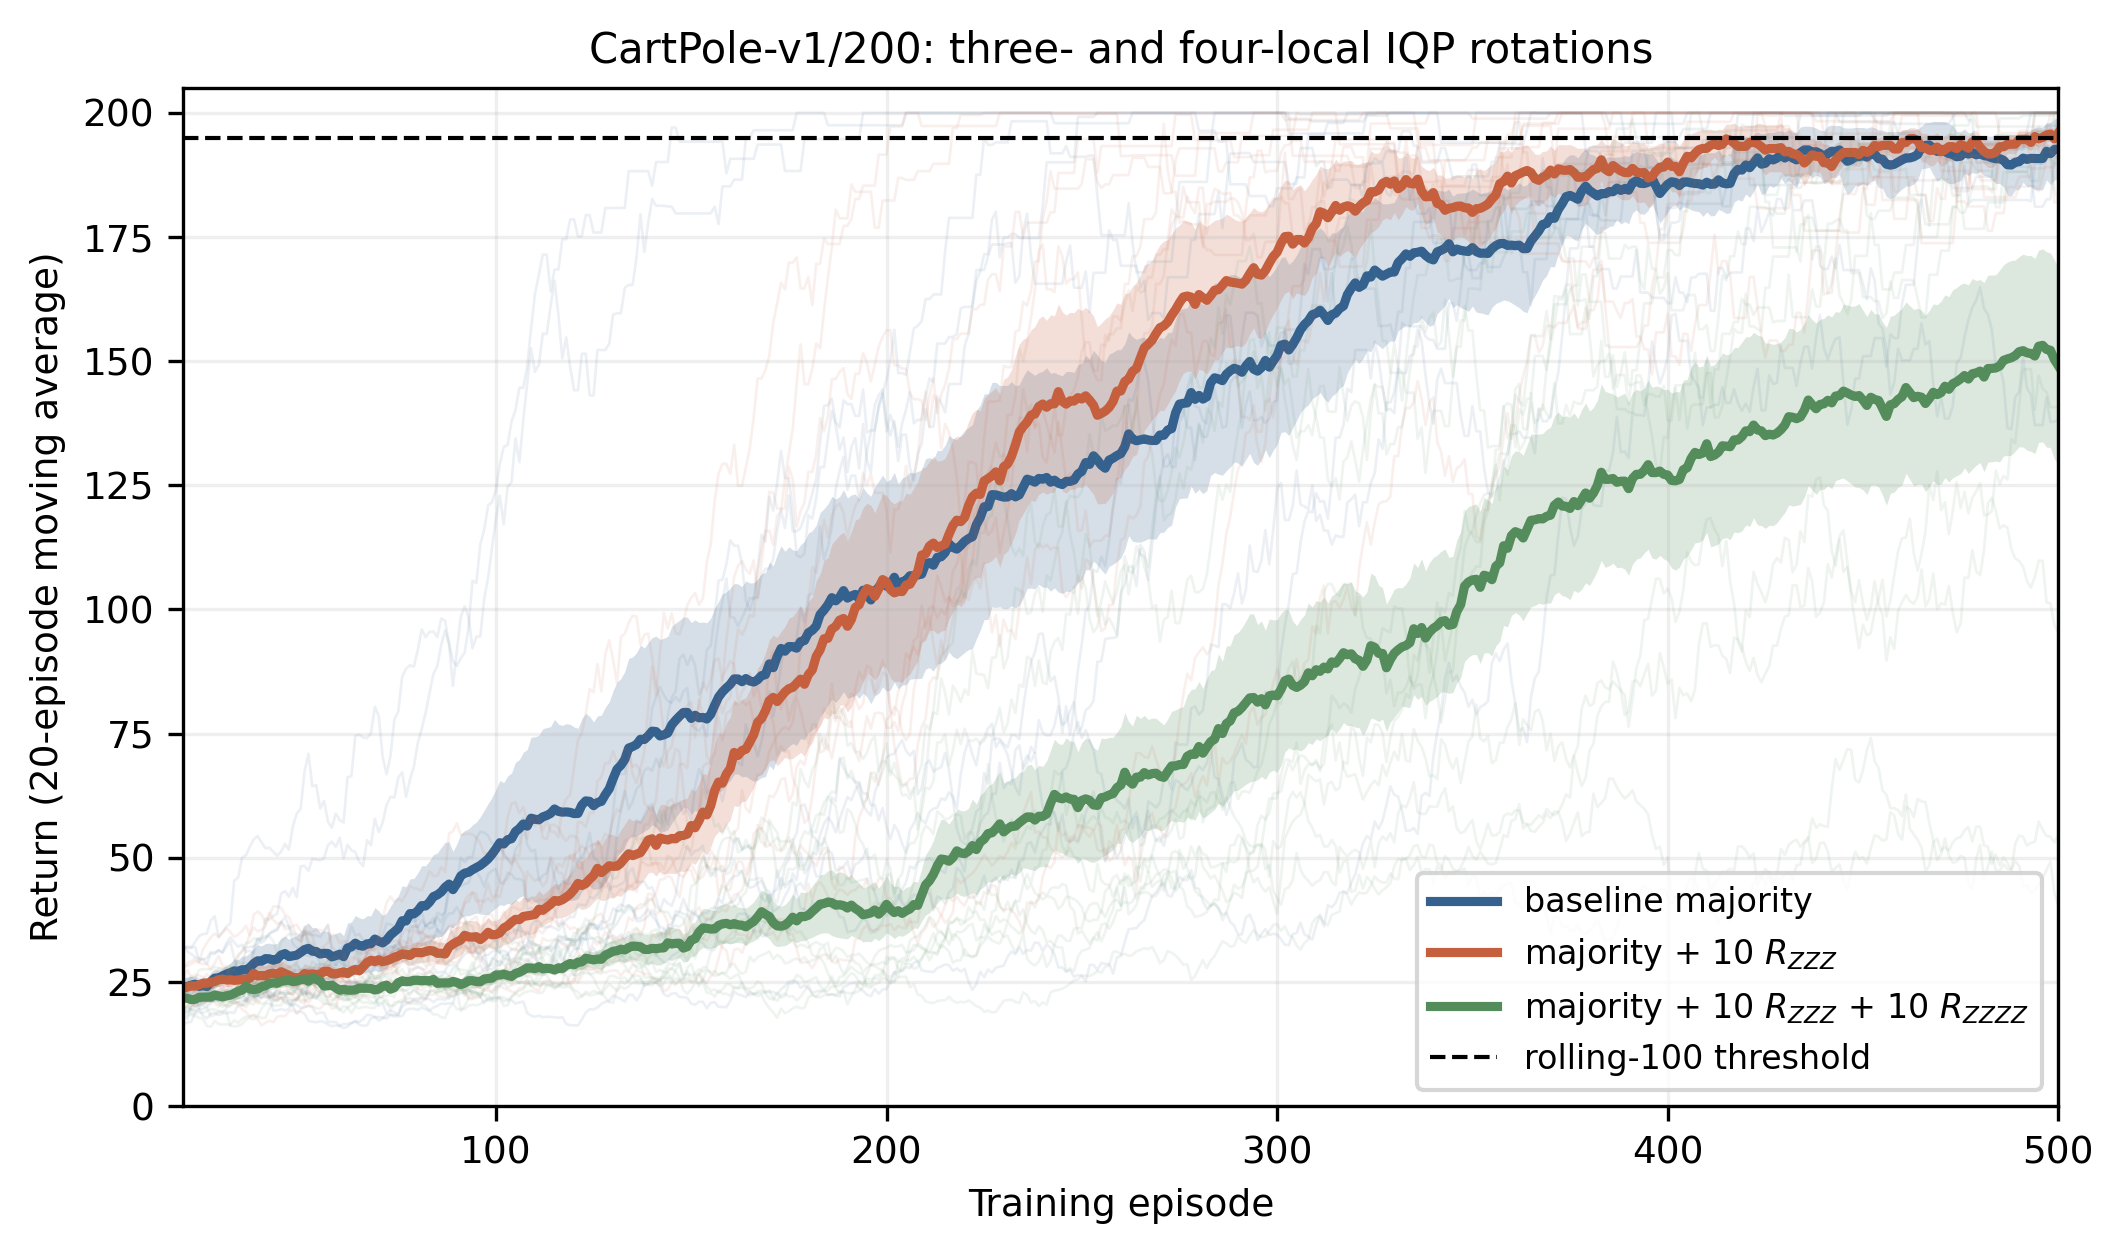

,condition,n_seeds,mean_training_final_50,sem_training_final_50,mean_heldout_evaluation,sem_heldout_evaluation,solved_seed_fraction
0,baseline majority,10,191.880,5.192838,194.687,2.057122,0.7
1,majority + 10 RZZZ,10,193.782,1.895120,195.889,1.602957,0.5
2,majority + 10 RZZZ + 10 RZZZZ,10,147.332,18.953241,154.678,17.943144,0.2


,contrast,n_pairs,mean_difference,bootstrap_ci95_low,bootstrap_ci95_high
0,new_minus_baseline_training_final_50,10,-44.548,-82.8820,-10.170000
1,new_minus_rzzz_training_final_50,10,-46.450,-83.5382,-13.212000
2,new_minus_baseline_heldout,10,-40.009,-77.4670,-8.804000
3,new_minus_rzzz_heldout,10,-41.211,-78.4660,-9.365925


In [8]:
def paired_bootstrap(values, reference, seed=20261025, n_boot=50_000):
    difference = np.asarray(values, float) - np.asarray(reference, float)
    rng = np.random.default_rng(seed)
    draws = rng.choice(difference, size=(n_boot, len(difference)), replace=True).mean(axis=1)
    return float(difference.mean()), tuple(np.quantile(draws, [0.025, 0.975]))


def aggregate_if_complete():
    records = []
    for seed in SEEDS:
        stem = RUNS_DIR / f"expander_10_L1__majority_rzzz10_rzzzz10__seed_{seed}"
        if not all(stem.with_suffix(suffix).exists() for suffix in (".npz", ".pt", ".json")):
            return None
        arrays = np.load(stem.with_suffix(".npz"))
        meta = json.loads(stem.with_suffix(".json").read_text())
        records.append((seed, arrays["training_returns"], arrays["evaluation_returns"], meta))

    four_local_train = {seed: train for seed, train, _, _ in records}
    four_local_eval = {seed: evaluation for seed, _, evaluation, _ in records}
    baseline_train_arrays = {
        seed: baseline_train[baseline_train.seed == seed].sort_values("episode")["return"].to_numpy(float)
        for seed in SEEDS
    }
    baseline_eval_arrays = {
        seed: baseline_eval[baseline_eval.seed == seed].sort_values("evaluation_episode")["return"].to_numpy(float)
        for seed in SEEDS
    }
    rzzz_train_arrays = {
        seed: rzzz_train[rzzz_train.seed == seed].sort_values("episode")["return"].to_numpy(float)
        for seed in SEEDS
    }
    rzzz_eval_arrays = {
        seed: rzzz_eval[rzzz_eval.seed == seed].sort_values("evaluation_episode")["return"].to_numpy(float)
        for seed in SEEDS
    }

    episode_rows, evaluation_rows, summary_rows = [], [], []
    for condition, training, evaluation in (
        ("baseline majority", baseline_train_arrays, baseline_eval_arrays),
        ("majority + 10 RZZZ", rzzz_train_arrays, rzzz_eval_arrays),
        ("majority + 10 RZZZ + 10 RZZZZ", four_local_train, four_local_eval),
    ):
        seed_final = []
        seed_eval = []
        for seed in SEEDS:
            seed_final.append(training[seed][-FINAL_WINDOW:].mean())
            seed_eval.append(evaluation[seed].mean())
            episode_rows.extend({"condition": condition, "seed": seed,
                                 "episode": i + 1, "return": value}
                                for i, value in enumerate(training[seed]))
            evaluation_rows.extend({"condition": condition, "seed": seed,
                                    "evaluation_episode": i + 1, "return": value}
                                   for i, value in enumerate(evaluation[seed]))
        summary_rows.append({
            "condition": condition, "n_seeds": len(SEEDS),
            "mean_training_final_50": float(np.mean(seed_final)),
            "sem_training_final_50": float(np.std(seed_final, ddof=1)/math.sqrt(len(SEEDS))),
            "mean_heldout_evaluation": float(np.mean(seed_eval)),
            "sem_heldout_evaluation": float(np.std(seed_eval, ddof=1)/math.sqrt(len(SEEDS))),
            "solved_seed_fraction": float(np.mean([
                np.nanmax(np.convolve(training[s], np.ones(100)/100, mode="valid")) >= 195
                for s in SEEDS
            ])),
        })

    episode_df = pd.DataFrame(episode_rows)
    evaluation_df = pd.DataFrame(evaluation_rows)
    summary_df = pd.DataFrame(summary_rows)
    episode_df.to_csv(RESULTS_DIR / "episode_returns.csv", index=False)
    evaluation_df.to_csv(RESULTS_DIR / "heldout_evaluation_returns.csv", index=False)
    summary_df.to_csv(RESULTS_DIR / "summary_metrics.csv", index=False)

    new_final = np.asarray([four_local_train[s][-FINAL_WINDOW:].mean() for s in SEEDS])
    rzzz_final = np.asarray([rzzz_train_arrays[s][-FINAL_WINDOW:].mean() for s in SEEDS])
    baseline_final = np.asarray([baseline_train_arrays[s][-FINAL_WINDOW:].mean() for s in SEEDS])
    new_heldout = np.asarray([four_local_eval[s].mean() for s in SEEDS])
    rzzz_heldout = np.asarray([rzzz_eval_arrays[s].mean() for s in SEEDS])
    baseline_heldout = np.asarray([baseline_eval_arrays[s].mean() for s in SEEDS])
    seed_summary_df = pd.DataFrame({
        "seed": SEEDS,
        "baseline_training_final_50": baseline_final,
        "rzzz_training_final_50": rzzz_final,
        "rzzz_rzzzz_training_final_50": new_final,
        "training_new_minus_baseline": new_final - baseline_final,
        "training_new_minus_rzzz": new_final - rzzz_final,
        "baseline_heldout_mean": baseline_heldout,
        "rzzz_heldout_mean": rzzz_heldout,
        "rzzz_rzzzz_heldout_mean": new_heldout,
        "heldout_new_minus_baseline": new_heldout - baseline_heldout,
        "heldout_new_minus_rzzz": new_heldout - rzzz_heldout,
    })
    seed_summary_df.to_csv(RESULTS_DIR / "seed_level_summary.csv", index=False)
    paired_rows = []
    for contrast, values, reference, boot_seed in (
        ("new_minus_baseline_training_final_50", new_final, baseline_final, 20261029),
        ("new_minus_rzzz_training_final_50", new_final, rzzz_final, 20261030),
        ("new_minus_baseline_heldout", new_heldout, baseline_heldout, 20261031),
        ("new_minus_rzzz_heldout", new_heldout, rzzz_heldout, 20261101),
    ):
        delta, interval = paired_bootstrap(values, reference, seed=boot_seed)
        paired_rows.append({"contrast": contrast, "n_pairs": len(SEEDS),
                            "mean_difference": delta,
                            "bootstrap_ci95_low": interval[0],
                            "bootstrap_ci95_high": interval[1]})
    paired_df = pd.DataFrame(paired_rows)
    paired_df.to_csv(RESULTS_DIR / "paired_comparisons.csv", index=False)

    rzzz_key = "majority + 10 RZZZ"
    new_key = "majority + 10 RZZZ + 10 RZZZZ"
    colors = {"baseline majority": "#35618f", rzzz_key: "#c65f3d", new_key: "#548c5b"}
    display_labels = {
        "baseline majority": "baseline majority",
        rzzz_key: r"majority + 10 $R_{ZZZ}$",
        new_key: r"majority + 10 $R_{ZZZ}$ + 10 $R_{ZZZZ}$",
    }
    fig, ax = plt.subplots(figsize=(7.15, 4.25), dpi=300)
    for condition, arrays in (("baseline majority", baseline_train_arrays),
                              (rzzz_key, rzzz_train_arrays),
                              (new_key, four_local_train)):
        curves = np.stack([np.convolve(arrays[s], np.ones(MOVING_WINDOW)/MOVING_WINDOW,
                                       mode="valid") for s in SEEDS])
        x = np.arange(MOVING_WINDOW, N_EPISODES + 1)
        for curve in curves:
            ax.plot(x, curve, color=colors[condition], alpha=0.09, linewidth=0.65)
        mean = curves.mean(axis=0)
        sem = curves.std(axis=0, ddof=1) / math.sqrt(len(SEEDS))
        ax.plot(x, mean, color=colors[condition], linewidth=2.2,
                label=display_labels[condition])
        ax.fill_between(x, np.clip(mean-sem, 0, 200), np.clip(mean+sem, 0, 200),
                        color=colors[condition], alpha=0.20, linewidth=0)
    ax.axhline(195, color="black", linestyle="--", linewidth=1.0,
               label="rolling-100 threshold")
    ax.set(xlabel="Training episode", ylabel="Return (20-episode moving average)",
           xlim=(MOVING_WINDOW, N_EPISODES), ylim=(0, 205),
           title=r"CartPole-v1/200: three- and four-local IQP rotations")
    ax.grid(alpha=0.2); ax.legend(loc="lower right")
    fig.tight_layout()
    fig.savefig(FIGURES_DIR / "cartpole_10q_majority_rzzz_rzzzz_learning_curves.pdf",
                bbox_inches="tight")
    fig.savefig(FIGURES_DIR / "cartpole_10q_majority_rzzz_rzzzz_learning_curves.png",
                dpi=300, bbox_inches="tight")
    plt.show()
    display(summary_df)
    display(paired_df)
    return summary_df, paired_df


aggregated = aggregate_if_complete()
if aggregated is None:
    print("No complete 10-seed augmented matrix yet; aggregation correctly deferred.")

## Durable metadata and manifest

The final cell records the selected triple and quartet sets, graph,
seeds, initialization audit, baseline provenance, software versions, run-level
costs, and checksums for every durable result.

In [9]:
software = {
    "python": sys.version, "platform": platform.platform(),
    "git_branch": CURRENT_BRANCH, "git_commit": CURRENT_COMMIT,
    "packages": {
        "qasp": getattr(qasp, "__version__", "0.1.0"),
        "pennylane": qml.__version__, "torch": torch.__version__,
        "gymnasium": gym.__version__, "numpy": np.__version__,
        "pandas": pd.__version__, "scipy": scipy.__version__,
        "joblib": joblib.__version__,
    },
}
completed = aggregated is not None
preflight = {
    "status": "complete" if completed else (
        "production_incomplete" if RUN_PRODUCTION else "configured_not_started"),
    "production_executed": bool(completed),
    "rzzz_gate_count": 10,
    "rzzzz_gate_count": 10,
    "rzzz_triple_master_seed": RZZZ_TRIPLE_MASTER_SEED,
    "rzzz_parameter_master_seed": RZZZ_PARAMETER_MASTER_SEED,
    "rzzzz_quartet_master_seed": RZZZZ_QUARTET_MASTER_SEED,
    "rzzzz_parameter_master_seed": RZZZZ_PARAMETER_MASTER_SEED,
    "selected_triples": [list(t) for t in SELECTED_TRIPLES],
    "selected_quartets": [list(q) for q in SELECTED_QUARTETS],
    "graph": {"master_seed": 31415, "accepted_networkx_seed": EXPECTED_GRAPH_SEED,
              "spectral_gap": graph_gap, "edges": [list(e) for e in EXPANDER_EDGES]},
    "measurement_wires": list(MEASUREMENT_WIRES),
    "coupled_unmeasured_wires": [9],
    "seeds": list(SEEDS), "training_episodes": N_EPISODES,
    "evaluation_episodes_per_seed": N_EVAL_EPISODES,
    "environment": "CartPole-v1/200", "training": TRAINING,
    "baseline_provenance": {
        "directory": str(BASELINE_DIR),
        "controlled_baseline_mean_final50": baseline_mean,
        "controlled_baseline_sem_final50": baseline_sem,
        "paper_historical_mean_final50": 192.13,
        "paper_historical_sem_final50": 5.23,
        "rzzz_control_directory": str(RZZZ_CONTROL_DIR),
        "pairing_uses": "controlled baseline and completed +10 RZZZ seed-level traces",
    },
    "preflight_gate_audit": preflight_rows,
    "software": software,
}
(RESULTS_DIR / "preflight_metadata.json").write_text(
    json.dumps(preflight, indent=2, allow_nan=True)
)

experiment_config = {
    "environment_label": "CartPole-v1/200",
    "gymnasium_environment_id": "CartPole-v1",
    "trainer_side_step_cap": MAX_STEPS,
    "training_episodes": N_EPISODES,
    "heldout_evaluation_episodes_per_seed": N_EVAL_EPISODES,
    "seeds": list(SEEDS), "training": TRAINING,
    "n_qubits": N_QUBITS, "n_layers": N_LAYERS,
    "graph_master_seed": 31415,
    "accepted_networkx_seed": EXPECTED_GRAPH_SEED,
    "spectral_gap": graph_gap,
    "edges": [list(edge) for edge in EXPANDER_EDGES],
    "measurement_wires": list(MEASUREMENT_WIRES),
    "coupled_unmeasured_wires": [9],
    "decoder": "deterministic majority on nine measured wires",
    "rzzz_gate_count": 10,
    "rzzzz_gate_count": 10,
    "selected_triples": [list(t) for t in SELECTED_TRIPLES],
    "selected_quartets": [list(q) for q in SELECTED_QUARTETS],
    "triple_selection": "fixed without replacement before training",
    "quartet_selection": "fixed without replacement before training",
    "rzzz_triple_master_seed": RZZZ_TRIPLE_MASTER_SEED,
    "rzzz_parameter_master_seed": RZZZ_PARAMETER_MASTER_SEED,
    "rzzzz_quartet_master_seed": RZZZZ_QUARTET_MASTER_SEED,
    "rzzzz_parameter_master_seed": RZZZZ_PARAMETER_MASTER_SEED,
    "shared_parameter_count": 65,
    "rzzz_control_parameter_count": 75,
    "augmented_parameter_count": 85,
    "baseline_source": str(BASELINE_DIR),
    "rzzz_control_source": str(RZZZ_CONTROL_DIR),
    "baseline_provenance_note": (
        "Paired inference reuses the compatible controlled 10-seed baseline "
        "(191.88 +/- 5.19), not the historical paper table aggregate "
        "(192.13 +/- 5.23)."
    ),
}
(RESULTS_DIR / "experiment_config.json").write_text(
    json.dumps(experiment_config, indent=2)
)
(RESULTS_DIR / "software_metadata.json").write_text(
    json.dumps(software, indent=2)
)

run_records = []
for path in sorted(RUNS_DIR.glob("*.json")):
    record = json.loads(path.read_text())
    if record.get("n_rzzz_gates") == 10 and record.get("n_rzzzz_gates") == 10:
        run_records.append(record)
run_metadata_df = pd.DataFrame(run_records).sort_values("seed") if run_records else pd.DataFrame()
run_metadata_df.to_csv(RESULTS_DIR / "run_metadata.csv", index=False)

audit_rows = []
if not run_metadata_df.empty:
    for row in run_metadata_df.itertuples(index=False):
        audit_rows.append({
            "seed": int(row.seed),
            "shared_tensors_bitwise_identical": (
                row.initial_shared_parameter_sha256 == row.baseline_shared_parameter_sha256
            ),
            "shared_parameter_sha256": row.initial_shared_parameter_sha256,
            "baseline_parameter_sha256": row.baseline_shared_parameter_sha256,
            "rzzz_parameters_match_prior_control": (
                row.initial_rzzz_parameter_sha256 == rzzz_hash_by_seed.loc[int(row.seed)]
            ),
            "rzzz_parameter_sha256": row.initial_rzzz_parameter_sha256,
            "rzzz_control_parameter_sha256": rzzz_hash_by_seed.loc[int(row.seed)],
            "rzzz_parameter_seed": int(row.rzzz_parameter_seed),
            "rzzzz_parameter_sha256": row.initial_rzzzz_parameter_sha256,
            "rzzzz_parameter_seed": int(row.rzzzz_parameter_seed),
            "n_rzzz_gates": int(row.n_rzzz_gates),
            "n_rzzzz_gates": int(row.n_rzzzz_gates),
        })
initialization_audit_df = pd.DataFrame(audit_rows)
initialization_audit_df.to_csv(
    RESULTS_DIR / "matched_initialization_audit.csv", index=False
)
if completed:
    assert len(run_metadata_df) == len(SEEDS)
    assert initialization_audit_df.shared_tensors_bitwise_identical.all()
    assert initialization_audit_df.rzzz_parameters_match_prior_control.all()

def file_sha256(path):
    digest = hashlib.sha256()
    with path.open("rb") as handle:
        for chunk in iter(lambda: handle.read(1 << 20), b""):
            digest.update(chunk)
    return digest.hexdigest()

manifest_files = []
for path in sorted(RESULTS_DIR.rglob("*")):
    if path.is_file() and path.name != "manifest.json":
        manifest_files.append({
            "path": str(path.relative_to(RESULTS_DIR)),
            "bytes": path.stat().st_size,
            "sha256": file_sha256(path),
        })
manifest = {
    "completed": bool(completed),
    "n_expected_augmented_runs": len(SEEDS),
    "n_completed_augmented_runs": len(run_metadata_df),
    "training_rows": (
        int(len(pd.read_csv(RESULTS_DIR / "episode_returns.csv")))
        if (RESULTS_DIR / "episode_returns.csv").exists() else 0
    ),
    "evaluation_rows": (
        int(len(pd.read_csv(RESULTS_DIR / "heldout_evaluation_returns.csv")))
        if (RESULTS_DIR / "heldout_evaluation_returns.csv").exists() else 0
    ),
    "all_cells_executed_from_clean_kernel": True,
    "total_augmented_training_seconds": (
        float(run_metadata_df.training_seconds.sum()) if not run_metadata_df.empty else 0.0
    ),
    "total_augmented_evaluation_seconds": (
        float(run_metadata_df.evaluation_seconds.sum()) if not run_metadata_df.empty else 0.0
    ),
    "total_augmented_training_circuit_calls": (
        int(run_metadata_df.training_forward_circuit_calls.sum())
        if not run_metadata_df.empty else 0
    ),
    "total_augmented_evaluation_circuit_calls": (
        int(run_metadata_df.evaluation_forward_circuit_calls.sum())
        if not run_metadata_df.empty else 0
    ),
    "files": manifest_files,
}
(RESULTS_DIR / "manifest.json").write_text(json.dumps(manifest, indent=2))

print("Saved reproducibility metadata and manifest in", RESULTS_DIR)
print("Notebook production status:", preflight["status"])
print("Completed augmented runs:", len(run_metadata_df), "/", len(SEEDS))

Saved reproducibility metadata and manifest in ./tests/results/cartpole_10q_majority_rzzz_rzzzz_ablation
Notebook production status: complete
Completed augmented runs: 10 / 10
